# StarCoder2-3B Fine-Tuned Model: Accuracy Matrix & Evaluation Benchmark

This notebook benchmarks the fine-tuned **`bigcode/starcoder2-3b`** model (with QLoRA adapter from `saved_models/starcoder2-3b-qlora-code-completion`) on the **CodeSearchNet Python** dataset.

### The Code Completion Accuracy Matrix
Standard language modeling perplexity alone does not fully capture code completion quality. In this notebook, we define and evaluate a multi-dimensional **Accuracy Matrix**:

1. **Strict Exact Match (EM %)**: The percentage of completions that match ground-truth reference code character-for-character.
2. **First-Line Exact Match (FLM %)**: Evaluates inline autocomplete accuracy by testing whether the immediate next statement/line matches ground truth.
3. **Edit Similarity (%)**: Character-level Levenshtein similarity ratio between generated and reference code (0–100%).
4. **Token-Level BLEU-4 (%)**: Measures n-gram overlap between generated code tokens and target tokens with brevity penalty.
5. **Python AST Syntax Validity (%)**: Verifies whether the combined `prompt + completion` compiles into a valid Python Abstract Syntax Tree via `ast.parse()`.
6. **Teacher-Forced Perplexity (PPL)**: Model confidence/cross-entropy loss evaluated specifically on completion tokens.
7. **Top-1 Token Prediction Accuracy (%)**: The percentage of completion token positions where `argmax(logits)` exactly matches the ground-truth token ID.
8. **Inference Latency & Throughput**: Milliseconds per completion and generation speed (tokens/second).


In [1]:
# 1. Imports and GPU Hardware Diagnostics
import os
import sys
import glob
import json
import math
import re
import time
import ast
import difflib
from collections import Counter

import numpy as np
import torch
import transformers
import peft
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

print(f"Python version:       {sys.version.split()[0]}")
print(f"PyTorch version:      {torch.__version__}")
print(f"Transformers version: {transformers.__version__}")
print(f"PEFT version:         {peft.__version__}")
print(f"CUDA Available:       {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    total_mem = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
    print(f"GPU Device:           {device_name} ({total_mem} GB VRAM)")
else:
    print("WARNING: CUDA is not available. Evaluation will run on CPU.")


Python version:       3.12.3
PyTorch version:      2.14.0+cu130
Transformers version: 5.17.0
PEFT version:         0.21.2
CUDA Available:       True
GPU Device:           NVIDIA GeForce RTX 4060 Laptop GPU (7.62 GB VRAM)


In [2]:
# 2. Benchmark Configuration & Path Resolution

MODEL_NAME = "bigcode/starcoder2-3b"

# Automatically resolve paths regardless of whether notebook is run from root or notebooks/
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "saved_models", "starcoder2-3b-qlora-code-completion")):
    BASE_DIR = cwd
elif os.path.exists(os.path.join(cwd, "..", "saved_models", "starcoder2-3b-qlora-code-completion")):
    BASE_DIR = os.path.abspath(os.path.join(cwd, ".."))
else:
    BASE_DIR = cwd

ADAPTER_DIR = os.path.join(BASE_DIR, "saved_models", "starcoder2-3b-qlora-code-completion")
DATASET_DIR = os.path.join(BASE_DIR, "dataset")

# ---- EVALUATION PARAMETERS ----
# Split to evaluate on: 'test' (unseen held-out), 'valid', or 'train'
SPLIT_CHOICE = "test"

# Number of samples to evaluate (e.g. 50 for a fast, representative benchmark)
NUM_EVAL_SAMPLES = 50

# Generation settings (Greedy decoding temperature=0.0 is standard for deterministic benchmarks)
MAX_NEW_TOKENS = 120
TEMPERATURE = 0.0
TOP_P = 0.95
MAX_CONTEXT_LENGTH = 1024
RANDOM_SEED = 42

print("BASE_DIR:           ", BASE_DIR)
print("ADAPTER_DIR:        ", ADAPTER_DIR)
print("DATASET_DIR:        ", DATASET_DIR)
print("Split:              ", SPLIT_CHOICE)
print("Sample Count:       ", NUM_EVAL_SAMPLES)
print("Adapter Exists:     ", os.path.exists(ADAPTER_DIR))


BASE_DIR:            /home/mastermind/Desktop/extras/CodeCompletionModel
ADAPTER_DIR:         /home/mastermind/Desktop/extras/CodeCompletionModel/saved_models/starcoder2-3b-qlora-code-completion
DATASET_DIR:         /home/mastermind/Desktop/extras/CodeCompletionModel/dataset
Split:               test
Sample Count:        50
Adapter Exists:      True


In [3]:
# 3. Load Tokenizer and Fine-Tuned Model (Base Model + QLoRA Adapter)

print("1. Loading Tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

print("2. Loading Base Model in 4-bit NF4 Precision...")
use_cuda = torch.cuda.is_available()
if use_cuda:
    use_bf16 = torch.cuda.is_bf16_supported()
    compute_dtype = torch.bfloat16 if use_bf16 else torch.float16
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )
    base_model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        quantization_config=bnb_config,
        torch_dtype=compute_dtype,
        device_map="auto",
    )
else:
    base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

print(f"3. Attaching Fine-Tuned LoRA Adapter from: {ADAPTER_DIR}")
model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()
model.config.use_cache = True

print("Fine-tuned model loaded and set to evaluation mode!")


1. Loading Tokenizer...


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 49151), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 49151), got 50256. This may result in unexpected behavior.


2. Loading Base Model in 4-bit NF4 Precision...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/483 [00:00<?, ?it/s]

3. Attaching Fine-Tuned LoRA Adapter from: /home/mastermind/Desktop/extras/CodeCompletionModel/saved_models/starcoder2-3b-qlora-code-completion
Fine-tuned model loaded and set to evaluation mode!


In [4]:
# 4. Dataset Loading & Prompt-Completion Boundary Extraction

def split_code_prompt_completion(code_text, docstring=None):
    """
    Splits a python function into a prompt context and reference completion.
    
    Strategy:
    1. If docstring exists, split right after the docstring closes
       (function signature + docstring -> prompt, function body -> completion).
    2. Fallback: Split after function header or first 30% lines of code.
    """
    if not code_text or not isinstance(code_text, str):
        return None, None

    code_clean = code_text.strip()
    
    # Strategy 1: Docstring boundary
    if docstring and isinstance(docstring, str) and docstring.strip() in code_clean:
        idx = code_clean.find(docstring.strip())
        after_doc = code_clean[idx + len(docstring.strip()):]
        # Match closing triple quotes
        closing_pos = -1
        triple_quotes = [chr(34) * 3, chr(39) * 3]
        for quote_marker in triple_quotes:
            if quote_marker in after_doc:
                pos = after_doc.find(quote_marker) + len(quote_marker)
                if closing_pos == -1 or pos < closing_pos:
                    closing_pos = pos
        if closing_pos != -1:
            split_idx = idx + len(docstring.strip()) + closing_pos
            prompt = code_clean[:split_idx]
            completion = code_clean[split_idx:]
            if prompt.strip() and completion.strip():
                return prompt, completion

    # Strategy 2: Line-based prefix split
    lines = code_clean.splitlines(keepends=True)
    if len(lines) >= 3:
        cut = max(1, min(len(lines) // 3, 5))
        prompt = "".join(lines[:cut])
        completion = "".join(lines[cut:])
        return prompt, completion

    return None, None


def load_dataset_samples(dataset_dir, split="test", max_samples=50, seed=42):
    """
    Loads JSONL records from the specified split and extracts prompt-completion pairs.
    """
    split_dir = os.path.join(dataset_dir, split)
    jsonl_files = sorted(glob.glob(os.path.join(split_dir, "*.jsonl")))
    
    if not jsonl_files:
        raise FileNotFoundError(f"No JSONL dataset files found in {split_dir}")
        
    print(f"Found {len(jsonl_files)} file(s) for split '{split}': {[os.path.basename(f) for f in jsonl_files]}")
    
    raw_records = []
    for file_path in jsonl_files:
        with open(file_path, "r", encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    raw_records.append(json.loads(line))
                if len(raw_records) >= max_samples * 4:
                    break
        if len(raw_records) >= max_samples * 4:
            break
            
    # Deterministic sampling using standard library random
    import random
    rng = random.Random(seed)
    indices = list(range(len(raw_records)))
    rng.shuffle(indices)
    
    valid_samples = []
    for idx in indices:
        record = raw_records[idx]
        code_str = record.get("original_string") or record.get("code") or ""
        docstring = record.get("docstring") or ""
        prompt, completion = split_code_prompt_completion(code_str, docstring)
        
        if prompt and completion and len(completion.strip()) > 15:
            valid_samples.append({
                "repo": record.get("repo", "unknown"),
                "func_name": record.get("func_name", "unknown"),
                "prompt": prompt,
                "reference_completion": completion,
                "full_code": code_str,
            })
            
        if len(valid_samples) >= max_samples:
            break
            
    print(f"Successfully loaded and formatted {len(valid_samples)} evaluation samples.")
    return valid_samples

eval_samples = load_dataset_samples(DATASET_DIR, split=SPLIT_CHOICE, max_samples=NUM_EVAL_SAMPLES, seed=RANDOM_SEED)


Found 1 file(s) for split 'test': ['python_test_0.jsonl']
Successfully loaded and formatted 50 evaluation samples.


In [5]:
# 5. Sanity Check: Inspect an Evaluation Sample
sample = eval_samples[0]
print("=" * 80)
print(f"SAMPLE 0: Function `{sample['func_name']}` (Repo: {sample['repo']})")
print("=" * 80)
print("--- [PROMPT CONTEXT (Given to Model)] ---")
print(sample["prompt"])
print("\n--- [GROUND TRUTH REFERENCE COMPLETION] ---")
ref_preview = sample["reference_completion"][:400]
if len(sample["reference_completion"]) > 400:
    ref_preview += "..."
print(ref_preview)
print("=" * 80)


SAMPLE 0: Function `MySqlHook.get_conn` (Repo: apache/airflow)
--- [PROMPT CONTEXT (Given to Model)] ---
def get_conn(self):
        """
        Returns a mysql connection object
        """

--- [GROUND TRUTH REFERENCE COMPLETION] ---

        conn = self.get_connection(self.mysql_conn_id)
        conn_config = {
            "user": conn.login,
            "passwd": conn.password or '',
            "host": conn.host or 'localhost',
            "db": self.schema or conn.schema or ''
        }

        if not conn.port:
            conn_config["port"] = 3306
        else:
            conn_config["port"] = int(conn.port)

        ...


In [6]:
# 6. Accuracy Matrix Metric Definitions

def compute_exact_match(pred: str, ref: str) -> bool:
    """Strict Exact Match (normalized whitespace / stripped)."""
    return pred.strip() == ref.strip()


def compute_first_line_match(pred: str, ref: str) -> bool:
    """
    Checks if the first non-empty line of the generated completion
    matches the first non-empty line of the reference completion.
    """
    pred_lines = [line.strip() for line in pred.splitlines() if line.strip()]
    ref_lines = [line.strip() for line in ref.splitlines() if line.strip()]
    if not pred_lines or not ref_lines:
        return False
    return pred_lines[0] == ref_lines[0]


def compute_edit_similarity(pred: str, ref: str) -> float:
    """
    Normalized character-level Levenshtein similarity ratio in [0, 100].
    Based on Gestalt pattern matching (Python difflib).
    """
    if not pred.strip() and not ref.strip():
        return 100.0
    matcher = difflib.SequenceMatcher(None, pred.strip(), ref.strip())
    return matcher.ratio() * 100.0


def tokenize_code(text: str):
    """Tokenizes code into keywords, identifiers, and punctuation symbols."""
    token_pattern = r"\w+|[^\w\s]"
    return [tok for tok in re.findall(token_pattern, text) if tok.strip()]


def compute_token_bleu(pred: str, ref: str, max_n: int = 4, smooth: bool = True) -> float:
    """
    Calculates BLEU-n score (0–100%) on tokenized code sequences with brevity penalty.
    """
    pred_toks = tokenize_code(pred)
    ref_toks = tokenize_code(ref)
    
    if not pred_toks or not ref_toks:
        return 0.0
        
    c = len(pred_toks)
    r = len(ref_toks)
    bp = 1.0 if c >= r else math.exp(1.0 - r / c)
    
    precisions = []
    for n in range(1, max_n + 1):
        if len(pred_toks) < n or len(ref_toks) < n:
            precisions.append(1.0 / (len(pred_toks) + 1) if smooth else 0.0)
            continue
            
        pred_ngrams = Counter(tuple(pred_toks[i:i+n]) for i in range(len(pred_toks) - n + 1))
        ref_ngrams = Counter(tuple(ref_toks[i:i+n]) for i in range(len(ref_toks) - n + 1))
        
        clipped = sum(min(cnt, ref_ngrams.get(ng, 0)) for ng, cnt in pred_ngrams.items())
        total = sum(pred_ngrams.values())
        p = (clipped + (1.0 if smooth else 0.0)) / (total + (1.0 if smooth else 0.0))
        precisions.append(p)
        
    if any(p <= 0 for p in precisions):
        return 0.0
        
    log_sum = sum(math.log(p) for p in precisions) / max_n
    return bp * math.exp(log_sum) * 100.0


def check_syntax_validity(prompt: str, completion: str) -> bool:
    """
    Tests whether combining prompt + completion produces syntactically valid Python code.
    """
    full_code = prompt + "\n" + completion
    try:
        ast.parse(full_code)
        return True
    except SyntaxError:
        return False


def compute_teacher_forced_metrics(model, tokenizer, prompt_text: str, ref_text: str, max_length: int = 1024):
    """
    Computes cross-entropy loss, perplexity, and top-1 token prediction accuracy
    on the reference completion tokens given the prompt context.
    """
    device = next(model.parameters()).device
    
    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    comp_ids = tokenizer(ref_text, add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    
    total_len = len(prompt_ids) + len(comp_ids)
    if total_len > max_length:
        comp_ids = comp_ids[:max(32, max_length - len(prompt_ids))]
        if len(prompt_ids) + len(comp_ids) > max_length:
            prompt_ids = prompt_ids[-(max_length - len(comp_ids)):]
            
    input_ids = torch.tensor([prompt_ids + comp_ids], device=device)
    labels = torch.tensor([[-100] * len(prompt_ids) + comp_ids], device=device)
    
    with torch.inference_mode():
        outputs = model(input_ids=input_ids, labels=labels)
        loss = outputs.loss.item()
        ppl = math.exp(min(loss, 80))
        
        shift_logits = outputs.logits[..., :-1, :].contiguous()
        shift_labels = labels[..., 1:].contiguous()
        mask = shift_labels != -100
        
        if mask.sum() > 0:
            preds = torch.argmax(shift_logits, dim=-1)
            correct = (preds[mask] == shift_labels[mask]).sum().item()
            total = mask.sum().item()
            token_acc = (correct / total) * 100.0
        else:
            token_acc = 0.0
            
    return {
        "loss": loss,
        "perplexity": ppl,
        "token_accuracy": token_acc,
    }


def generate_code_completion(model, tokenizer, prompt_text: str, max_new_tokens: int = 120, temperature: float = 0.0, top_p: float = 0.95):
    """
    Generates completion tokens from the model given the prompt.
    Returns: generated completion text, generation latency (sec), token count.
    """
    device = next(model.parameters()).device
    inputs = tokenizer(prompt_text, return_tensors="pt", truncation=True, max_length=MAX_CONTEXT_LENGTH).to(device)
    prompt_len = inputs["input_ids"].shape[1]
    
    gen_kwargs = {
        "max_new_tokens": max_new_tokens,
        "pad_token_id": tokenizer.pad_token_id,
        "eos_token_id": tokenizer.eos_token_id,
        "use_cache": True,
    }
    if temperature > 0:
        gen_kwargs.update({"do_sample": True, "temperature": temperature, "top_p": top_p})
    else:
        gen_kwargs["do_sample"] = False
        
    start_time = time.perf_counter()
    with torch.inference_mode():
        outputs = model.generate(**inputs, **gen_kwargs)
    elapsed = time.perf_counter() - start_time
    
    gen_ids = outputs[0][prompt_len:]
    completion = tokenizer.decode(gen_ids, skip_special_tokens=True)
    num_tokens = len(gen_ids)
    
    return completion, elapsed, num_tokens


In [7]:
# 7. Execute the Evaluation Benchmark Pipeline

results = []
print(f"Beginning evaluation on {len(eval_samples)} samples from '{SPLIT_CHOICE}' split...")
start_benchmark = time.time()

for i, sample in enumerate(eval_samples, 1):
    prompt = sample["prompt"]
    reference = sample["reference_completion"]
    
    # 1. Generate code completion
    generated_code, latency, num_gen_tokens = generate_code_completion(
        model, tokenizer, prompt, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P
    )
    tokens_per_sec = num_gen_tokens / latency if latency > 0 else 0.0
    
    # 2. Compute Generation Accuracy Metrics
    em = compute_exact_match(generated_code, reference)
    flm = compute_first_line_match(generated_code, reference)
    edit_sim = compute_edit_similarity(generated_code, reference)
    bleu4 = compute_token_bleu(generated_code, reference, max_n=4)
    bleu2 = compute_token_bleu(generated_code, reference, max_n=2)
    syntax_ok = check_syntax_validity(prompt, generated_code)
    
    # 3. Compute Teacher-Forced Probabilistic Metrics
    tf_metrics = compute_teacher_forced_metrics(model, tokenizer, prompt, reference)
    
    res = {
        "index": i,
        "func_name": sample["func_name"],
        "repo": sample["repo"],
        "prompt": prompt,
        "reference": reference,
        "prediction": generated_code,
        "exact_match": em,
        "first_line_match": flm,
        "edit_similarity": edit_sim,
        "bleu4": bleu4,
        "bleu2": bleu2,
        "syntax_valid": syntax_ok,
        "eval_loss": tf_metrics["loss"],
        "perplexity": tf_metrics["perplexity"],
        "token_accuracy": tf_metrics["token_accuracy"],
        "latency_ms": latency * 1000.0,
        "tokens_per_sec": tokens_per_sec,
    }
    results.append(res)
    
    if i % 10 == 0 or i == len(eval_samples):
        print(f"[{i:02d}/{len(eval_samples)}] "
              f"EditSim: {edit_sim:5.1f}% | BLEU-4: {bleu4:5.1f}% | "
              f"TokenAcc: {tf_metrics['token_accuracy']:5.1f}% | "
              f"Syntax: {'✓' if syntax_ok else '✗'} | "
              f"Speed: {tokens_per_sec:4.1f} tok/s")

total_time = time.time() - start_benchmark
print(f"\nEvaluation complete! Processed {len(results)} samples in {total_time:.2f} seconds.")


Beginning evaluation on 50 samples from 'test' split...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[10/50] EditSim:   9.5% | BLEU-4:   1.5% | TokenAcc:  81.4% | Syntax: ✓ | Speed: 31.3 tok/s
[20/50] EditSim:  13.6% | BLEU-4:   0.1% | TokenAcc:  79.0% | Syntax: ✓ | Speed: 33.3 tok/s
[30/50] EditSim:  15.3% | BLEU-4:   0.0% | TokenAcc:  80.0% | Syntax: ✓ | Speed: 31.7 tok/s
[40/50] EditSim:  41.5% | BLEU-4:   5.7% | TokenAcc:  80.0% | Syntax: ✓ | Speed: 31.6 tok/s
[50/50] EditSim:   6.1% | BLEU-4:   0.0% | TokenAcc:  59.7% | Syntax: ✓ | Speed: 30.4 tok/s

Evaluation complete! Processed 50 samples in 112.44 seconds.


In [8]:
# 8. The Accuracy Matrix (Summary Table)

# Calculate aggregate metrics
try:
    import numpy as np
    calc_mean = np.mean
    calc_median = np.median
except ImportError:
    import statistics
    calc_mean = lambda vals: sum(vals) / len(vals) if vals else 0.0
    calc_median = lambda vals: statistics.median(vals) if vals else 0.0

n_total = len(results)
em_rate = sum(r["exact_match"] for r in results) / n_total * 100.0
flm_rate = sum(r["first_line_match"] for r in results) / n_total * 100.0
avg_edit_sim = calc_mean([r["edit_similarity"] for r in results])
median_edit_sim = calc_median([r["edit_similarity"] for r in results])
avg_bleu4 = calc_mean([r["bleu4"] for r in results])
avg_bleu2 = calc_mean([r["bleu2"] for r in results])
syntax_rate = sum(r["syntax_valid"] for r in results) / n_total * 100.0
avg_loss = calc_mean([r["eval_loss"] for r in results])
avg_ppl = math.exp(min(avg_loss, 80))
avg_token_acc = calc_mean([r["token_accuracy"] for r in results])
median_token_acc = calc_median([r["token_accuracy"] for r in results])
avg_latency_ms = calc_mean([r["latency_ms"] for r in results])
avg_throughput = calc_mean([r["tokens_per_sec"] for r in results])

matrix_rows = [
    {"Metric Category": "Strict Completion", "Metric Name": "Strict Exact Match (EM)", "Value": f"{em_rate:.2f}%", "Description": "Exact character match on full function body"},
    {"Metric Category": "Line Completion",   "Metric Name": "First-Line Match (FLM)",  "Value": f"{flm_rate:.2f}%", "Description": "Accuracy of immediate next code statement"},
    {"Metric Category": "Fuzzy Matching",    "Metric Name": "Average Edit Similarity", "Value": f"{avg_edit_sim:.2f}%", "Description": f"Levenshtein character similarity (Median: {median_edit_sim:.2f}%)"},
    {"Metric Category": "N-Gram Overlap",    "Metric Name": "Token BLEU-4 Score",      "Value": f"{avg_bleu4:.2f}%", "Description": f"4-gram precision with brevity penalty (BLEU-2: {avg_bleu2:.2f}%)"},
    {"Metric Category": "Code Quality",      "Metric Name": "AST Syntax Validity Rate","Value": f"{syntax_rate:.2f}%", "Description": "Python ast.parse() compilation pass rate"},
    {"Metric Category": "Language Modeling", "Metric Name": "Top-1 Token Accuracy",    "Value": f"{avg_token_acc:.2f}%", "Description": f"Teacher-forced argmax token prediction (Median: {median_token_acc:.2f}%)"},
    {"Metric Category": "Language Modeling", "Metric Name": "Teacher-Forced Perplexity","Value": f"{avg_ppl:.2f}", "Description": "exp(eval_loss) on reference completion tokens"},
    {"Metric Category": "Performance",       "Metric Name": "Generation Latency",     "Value": f"{avg_latency_ms:.1f} ms", "Description": "Average completion time per sample"},
    {"Metric Category": "Performance",       "Metric Name": "Throughput",             "Value": f"{avg_throughput:.1f} tok/s", "Description": "Tokens generated per second (4-bit NF4)"},
]

print("=" * 95)
print(f"STARCODER2-3B QLoRA ACCURACY MATRIX (Split: {SPLIT_CHOICE.upper()}, N = {n_total})")
print("=" * 95)
print(f"{'CATEGORY':<20} | {'METRIC NAME':<28} | {'VALUE':<12} | {'DESCRIPTION'}")
print("-" * 95)
for row in matrix_rows:
    print(f"{row['Metric Category']:<20} | {row['Metric Name']:<28} | {row['Value']:<12} | {row['Description']}")
print("=" * 95)

try:
    import pandas as pd
    df_matrix = pd.DataFrame(matrix_rows)
    display(df_matrix)
except (ImportError, NameError):
    pass


STARCODER2-3B QLoRA ACCURACY MATRIX (Split: TEST, N = 50)
CATEGORY             | METRIC NAME                  | VALUE        | DESCRIPTION
-----------------------------------------------------------------------------------------------
Strict Completion    | Strict Exact Match (EM)      | 0.00%        | Exact character match on full function body
Line Completion      | First-Line Match (FLM)       | 6.00%        | Accuracy of immediate next code statement
Fuzzy Matching       | Average Edit Similarity      | 17.06%       | Levenshtein character similarity (Median: 11.94%)
N-Gram Overlap       | Token BLEU-4 Score           | 8.86%        | 4-gram precision with brevity penalty (BLEU-2: 14.99%)
Code Quality         | AST Syntax Validity Rate     | 86.00%       | Python ast.parse() compilation pass rate
Language Modeling    | Top-1 Token Accuracy         | 77.09%       | Teacher-forced argmax token prediction (Median: 78.64%)
Language Modeling    | Teacher-Forced Perplexity    | 2.65     

,Metric Category,Metric Name,Value,Description
0,Strict Completion,Strict Exact Match (EM),0.00%,Exact character match on full function body
1,Line Completion,First-Line Match (FLM),6.00%,Accuracy of immediate next code statement
2,Fuzzy Matching,Average Edit Similarity,17.06%,Levenshtein character similarity (Median: 11.94%)
3,N-Gram Overlap,Token BLEU-4 Score,8.86%,4-gram precision with brevity penalty (BLEU-2:...
4,Code Quality,AST Syntax Validity Rate,86.00%,Python ast.parse() compilation pass rate
5,Language Modeling,Top-1 Token Accuracy,77.09%,Teacher-forced argmax token prediction (Median...
6,Language Modeling,Teacher-Forced Perplexity,2.65,exp(eval_loss) on reference completion tokens
7,Performance,Generation Latency,2117.6 ms,Average completion time per sample
8,Performance,Throughput,32.0 tok/s,Tokens generated per second (4-bit NF4)


In [9]:
# 9. Qualitative Inspection: Side-by-Side Completion Samples

sorted_results = sorted(results, key=lambda x: x["edit_similarity"], reverse=True)

print("=" * 80)
print("TOP-PERFORMING CODE COMPLETION SAMPLES")
print("=" * 80)

for idx in [0, min(1, len(sorted_results)-1)]:
    sample_res = sorted_results[idx]
    syntax_str = "Valid" if sample_res["syntax_valid"] else "Invalid"
    print(f"\n[Rank #{idx+1}] Function `{sample_res['func_name']}` (Edit Sim: {sample_res['edit_similarity']:.1f}%, BLEU-4: {sample_res['bleu4']:.1f}%, Syntax: {syntax_str})")
    print("-" * 80)
    print("PROMPT:")
    print(sample_res["prompt"].strip())
    print("\n--- MODEL COMPLETION ---")
    print(sample_res["prediction"].strip())
    print("\n--- GROUND TRUTH REFERENCE ---")
    print(sample_res["reference"].strip())
    print("=" * 80)

if len(sorted_results) > 2:
    med_idx = len(sorted_results) // 2
    med_sample = sorted_results[med_idx]
    print(f"\n[MEDIAN CASE Rank #{med_idx+1}] Function `{med_sample['func_name']}` (Edit Sim: {med_sample['edit_similarity']:.1f}%, BLEU-4: {med_sample['bleu4']:.1f}%)")
    print("-" * 80)
    print("PROMPT:")
    print(med_sample["prompt"].strip())
    print("\n--- MODEL COMPLETION ---")
    print(med_sample["prediction"].strip())
    print("\n--- GROUND TRUTH REFERENCE ---")
    print(med_sample["reference"].strip())
    print("=" * 80)


TOP-PERFORMING CODE COMPLETION SAMPLES

[Rank #1] Function `match1` (Edit Sim: 78.7%, BLEU-4: 71.2%, Syntax: Valid)
--------------------------------------------------------------------------------
PROMPT:
def match1(text, *patterns):
    """Scans through a string for substrings matched some patterns (first-subgroups only).

    Args:
        text: A string to be scanned.
        patterns: Arbitrary number of regex patterns.

    Returns:
        When only one pattern is given, returns a string (None if no match found).
        When more than one pattern are given, returns a list of strings ([] if no match found).
    """

--- MODEL COMPLETION ---
if len(patterns) == 1:
        pattern = patterns[0]
        match = pattern.search(text)
        if match:
            return match.group(1)
        else:
            return None
    else:
        matches = []
        for pattern in patterns:
            match = pattern.search(text)
            if match:
                matches.append(match.g

Full benchmark data successfully exported to: /home/mastermind/Desktop/extras/CodeCompletionModel/evaluation_results.json
Performance plot saved to: /home/mastermind/Desktop/extras/CodeCompletionModel/evaluation_metrics_plot.png


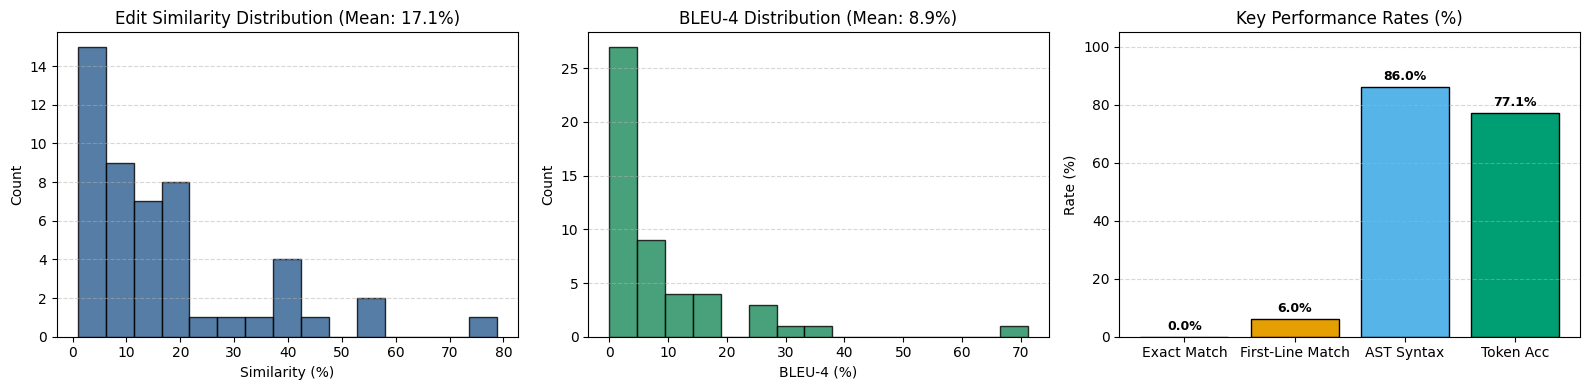

In [10]:
# 10. Metric Visualizations and Export Results
import os
import json

export_path = os.path.join(BASE_DIR, "evaluation_results.json")
export_data = {
    "model_name": MODEL_NAME,
    "adapter_dir": ADAPTER_DIR,
    "split": SPLIT_CHOICE,
    "num_samples": len(results),
    "accuracy_matrix": {
        "strict_exact_match_pct": em_rate,
        "first_line_match_pct": flm_rate,
        "mean_edit_similarity_pct": avg_edit_sim,
        "median_edit_similarity_pct": median_edit_sim,
        "mean_bleu4_pct": avg_bleu4,
        "mean_bleu2_pct": avg_bleu2,
        "ast_syntax_validity_pct": syntax_rate,
        "mean_token_accuracy_pct": avg_token_acc,
        "mean_perplexity": avg_ppl,
        "mean_eval_loss": avg_loss,
        "avg_latency_ms": avg_latency_ms,
        "avg_throughput_tokens_per_sec": avg_throughput,
    },
    "per_sample_results": [
        {
            "index": r["index"],
            "func_name": r["func_name"],
            "repo": r["repo"],
            "exact_match": r["exact_match"],
            "first_line_match": r["first_line_match"],
            "edit_similarity": r["edit_similarity"],
            "bleu4": r["bleu4"],
            "syntax_valid": r["syntax_valid"],
            "token_accuracy": r["token_accuracy"],
            "eval_loss": r["eval_loss"],
            "tokens_per_sec": r["tokens_per_sec"],
        }
        for r in results
    ]
}

with open(export_path, "w", encoding="utf-8") as f:
    json.dump(export_data, f, indent=2)
print(f"Full benchmark data successfully exported to: {export_path}")

try:
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    
    # 1. Edit Similarity distribution
    edit_sims = [r["edit_similarity"] for r in results]
    axes[0].hist(edit_sims, bins=15, color="#2b5c8f", edgecolor="black", alpha=0.8)
    axes[0].set_title(f"Edit Similarity Distribution (Mean: {avg_edit_sim:.1f}%)")
    axes[0].set_xlabel("Similarity (%)")
    axes[0].set_ylabel("Count")
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)
    
    # 2. BLEU-4 distribution
    bleus = [r["bleu4"] for r in results]
    axes[1].hist(bleus, bins=15, color="#1b8a5a", edgecolor="black", alpha=0.8)
    axes[1].set_title(f"BLEU-4 Distribution (Mean: {avg_bleu4:.1f}%)")
    axes[1].set_xlabel("BLEU-4 (%)")
    axes[1].set_ylabel("Count")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)
    
    # 3. Key Rates Bar Chart
    rates = [em_rate, flm_rate, syntax_rate, avg_token_acc]
    rate_labels = ["Exact Match", "First-Line Match", "AST Syntax", "Token Acc"]
    bars = axes[2].bar(rate_labels, rates, color=["#c94a29", "#e69f00", "#56b4e9", "#009e73"], edgecolor="black")
    axes[2].set_title("Key Performance Rates (%)")
    axes[2].set_ylabel("Rate (%)")
    axes[2].set_ylim(0, 105)
    axes[2].grid(axis="y", linestyle="--", alpha=0.5)
    for bar in bars:
        height = bar.get_height()
        axes[2].annotate(f"{height:.1f}%",
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3), textcoords="offset points",
                         ha="center", va="bottom", fontsize=9, fontweight="bold")
                         
    plt.tight_layout()
    plot_path = os.path.join(BASE_DIR, "evaluation_metrics_plot.png")
    plt.savefig(plot_path, dpi=200)
    print(f"Performance plot saved to: {plot_path}")
    plt.show()
except ImportError:
    print("Note: matplotlib not found; visual plot skipped. Metric table and JSON export complete.")
